<a href="https://colab.research.google.com/github/bhaskar-025/heart-disease-prediction_ml_project/blob/main/heart_disease_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ❤️ Heart Disease Prediction — End-to-End Machine Learning Project

**Goal:** Predict whether a patient has heart disease from clinical features.

**What this notebook covers**
1. Data loading & understanding
2. Data quality checks & cleaning
3. Exploratory Data Analysis (EDA)
4. Leak-free preprocessing with `Pipeline` + `ColumnTransformer`
5. Training 12 ML models and comparing them with 5-fold cross-validation
6. Hyperparameter tuning of the best models
7. Ensemble models (Voting & Stacking)
8. Evaluation: confusion matrix, ROC curve, precision-recall, classification report
9. Model explainability (feature importance)
10. Saving the final model and predicting for a new patient

**Dataset:** Heart Failure Prediction / Heart Disease Dataset (Kaggle) — 918 patients, 11 features + target `HeartDisease`.

## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV, learning_curve)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

# Optional boosting libraries (install with: pip install xgboost lightgbm)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
print('XGBoost available :', HAS_XGB)
print('LightGBM available:', HAS_LGBM)

XGBoost available : True
LightGBM available: True


## 2. Load the Dataset

In [2]:
# --- Option A: download from Kaggle (uncomment in Google Colab, upload kaggle.json first) ---
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d johnsmith88/heart-disease-dataset
# import zipfile; zipfile.ZipFile('heart-disease-dataset.zip').extractall('.')

# --- Option B: upload heart.csv manually (Colab) ---
# from google.colab import files; files.upload()

df = pd.read_csv('heart.csv')
print('Shape:', df.shape)
df.head()

Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Data Understanding

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [5]:
print('Duplicate rows :', df.duplicated().sum())
print('\nMissing values per column:')
print(df.isnull().sum())

Duplicate rows : 0

Missing values per column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


HeartDisease
1    508
0    410
Name: count, dtype: int64
HeartDisease
1    55.34 %
0    44.66 %
Name: count, dtype: object


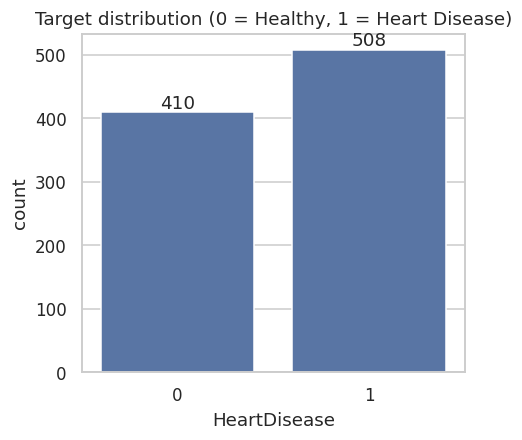

In [6]:
# Target balance
counts = df['HeartDisease'].value_counts()
print(counts)
print((counts / len(df) * 100).round(2).astype(str) + ' %')

plt.figure(figsize=(4.5, 4))
ax = sns.countplot(x='HeartDisease', data=df)
ax.bar_label(ax.containers[0])
plt.title('Target distribution (0 = Healthy, 1 = Heart Disease)')
plt.show()

## 4. Data Quality Check & Cleaning

Some columns contain **physiologically impossible zeros** (e.g. `Cholesterol = 0`, `RestingBP = 0`). These are really *missing values*.
We convert them to `NaN` and impute later **inside the pipeline** (so no information leaks from the test set).

In [7]:
print('Cholesterol == 0 :', (df['Cholesterol'] == 0).sum())
print('RestingBP   == 0 :', (df['RestingBP'] == 0).sum())

df_clean = df.drop_duplicates().copy()
df_clean[['Cholesterol', 'RestingBP']] = df_clean[['Cholesterol', 'RestingBP']].replace(0, np.nan)
print('\nMissing after treating zeros as NaN:')
print(df_clean.isnull().sum()[lambda s: s > 0])

Cholesterol == 0 : 172
RestingBP   == 0 : 1

Missing after treating zeros as NaN:
RestingBP        1
Cholesterol    172
dtype: int64


## 5. Exploratory Data Analysis (EDA)

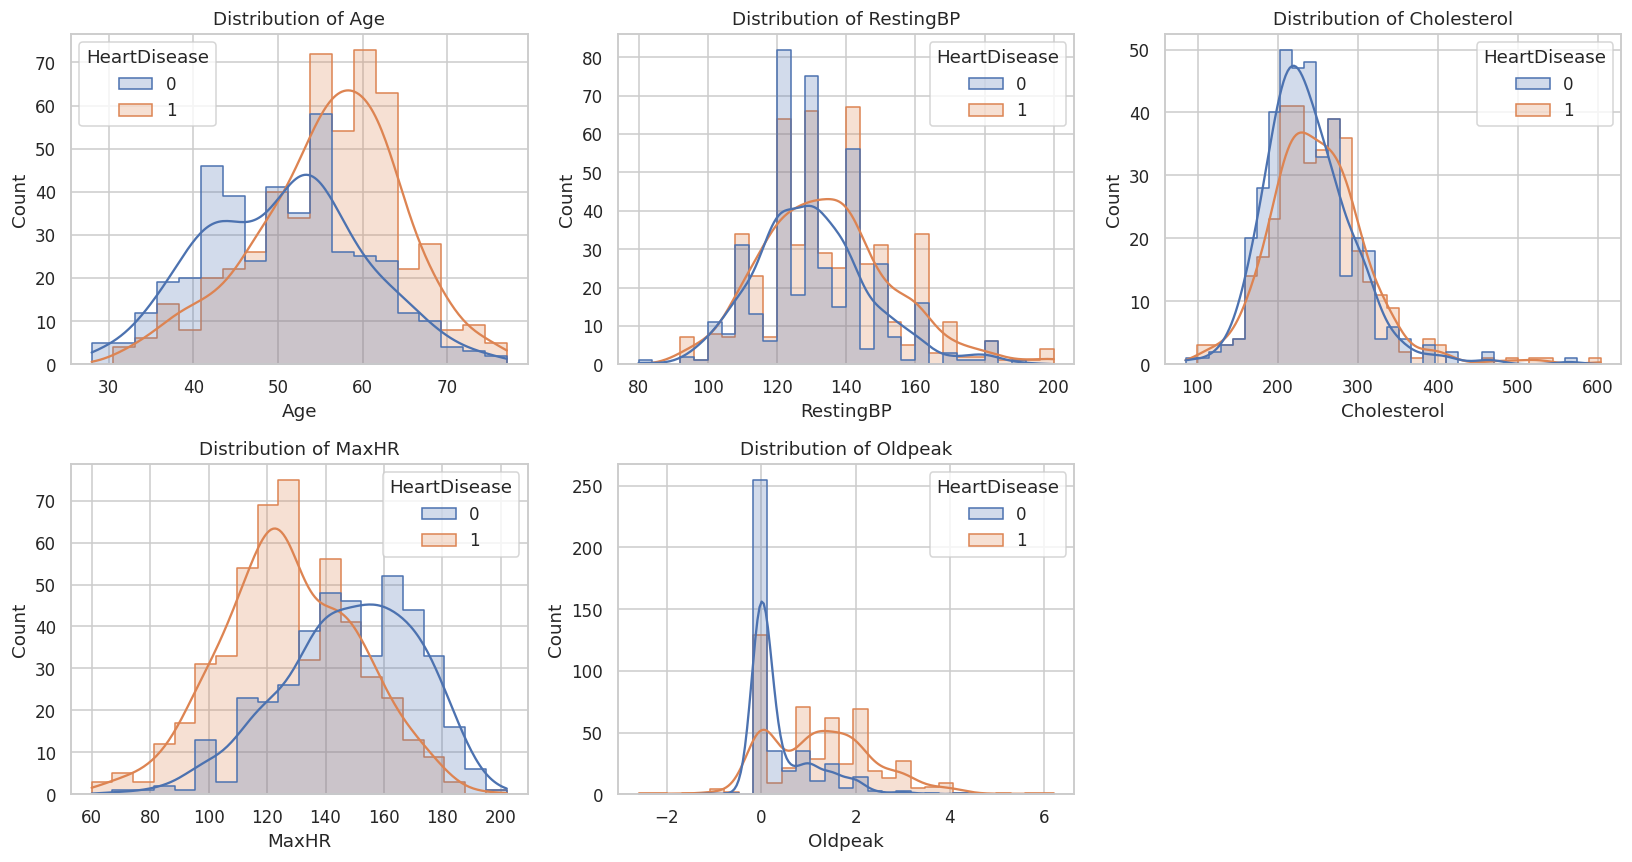

In [8]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df_clean, x=col, hue='HeartDisease', kde=True, ax=ax, element='step')
    ax.set_title(f'Distribution of {col}')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

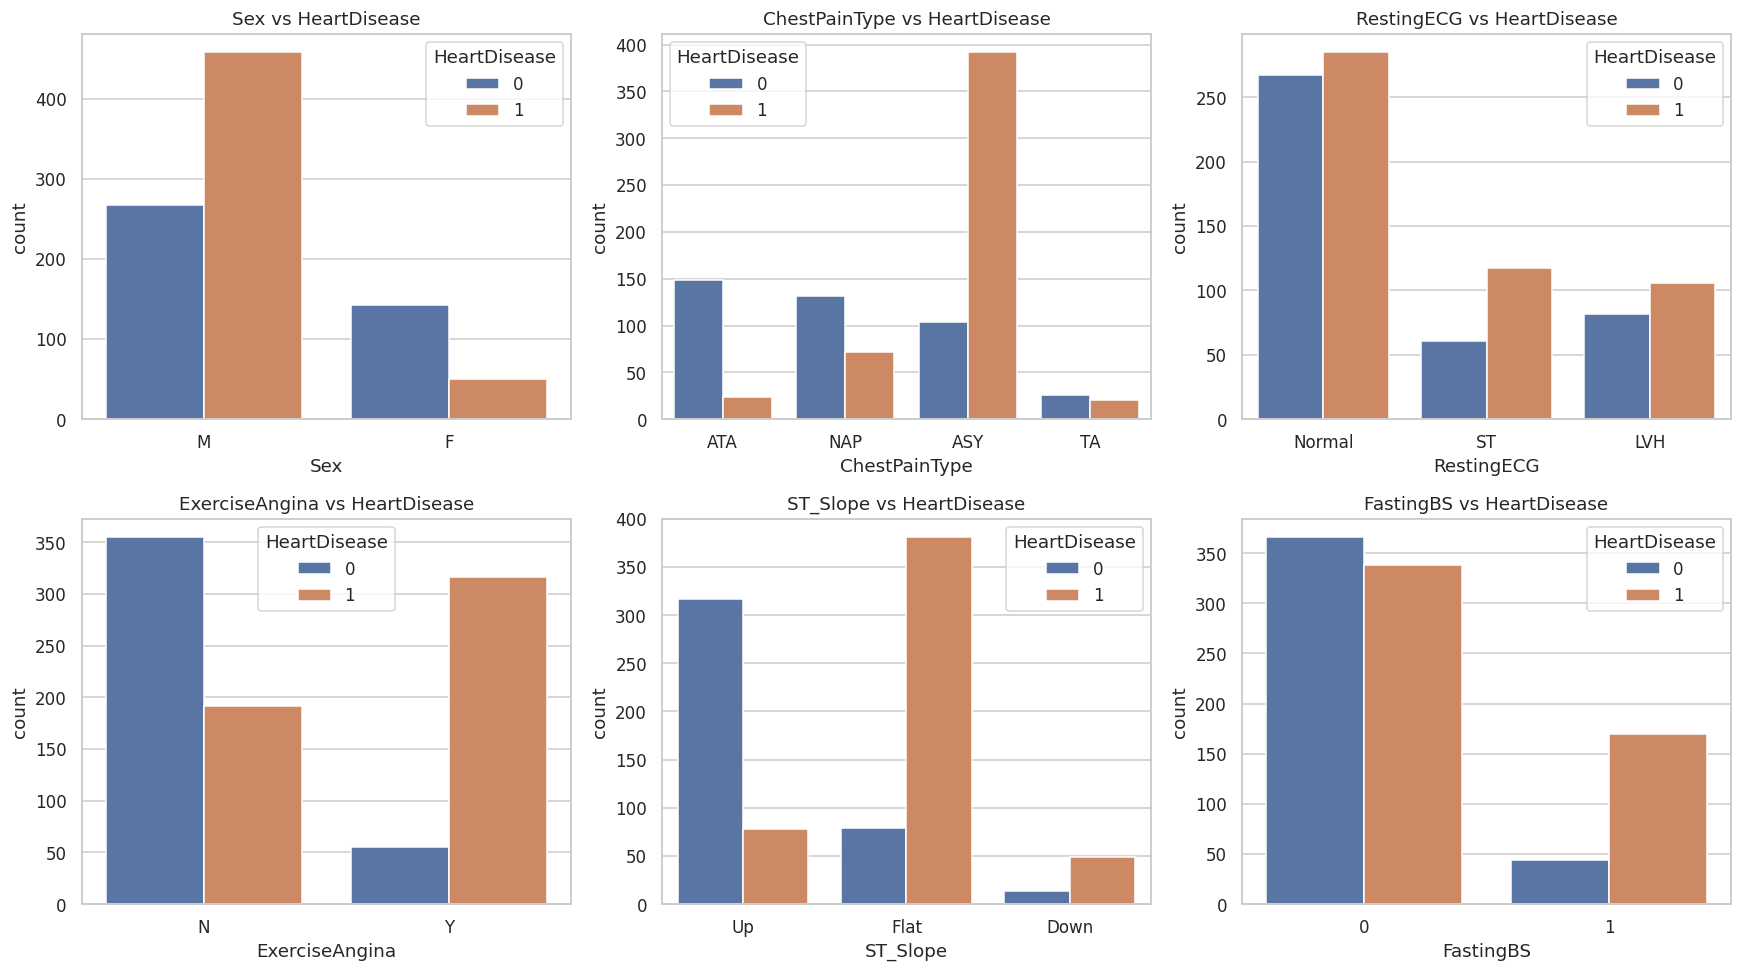

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_cols + ['FastingBS']):
    sns.countplot(data=df_clean, x=col, hue='HeartDisease', ax=ax)
    ax.set_title(f'{col} vs HeartDisease')
plt.tight_layout(); plt.show()

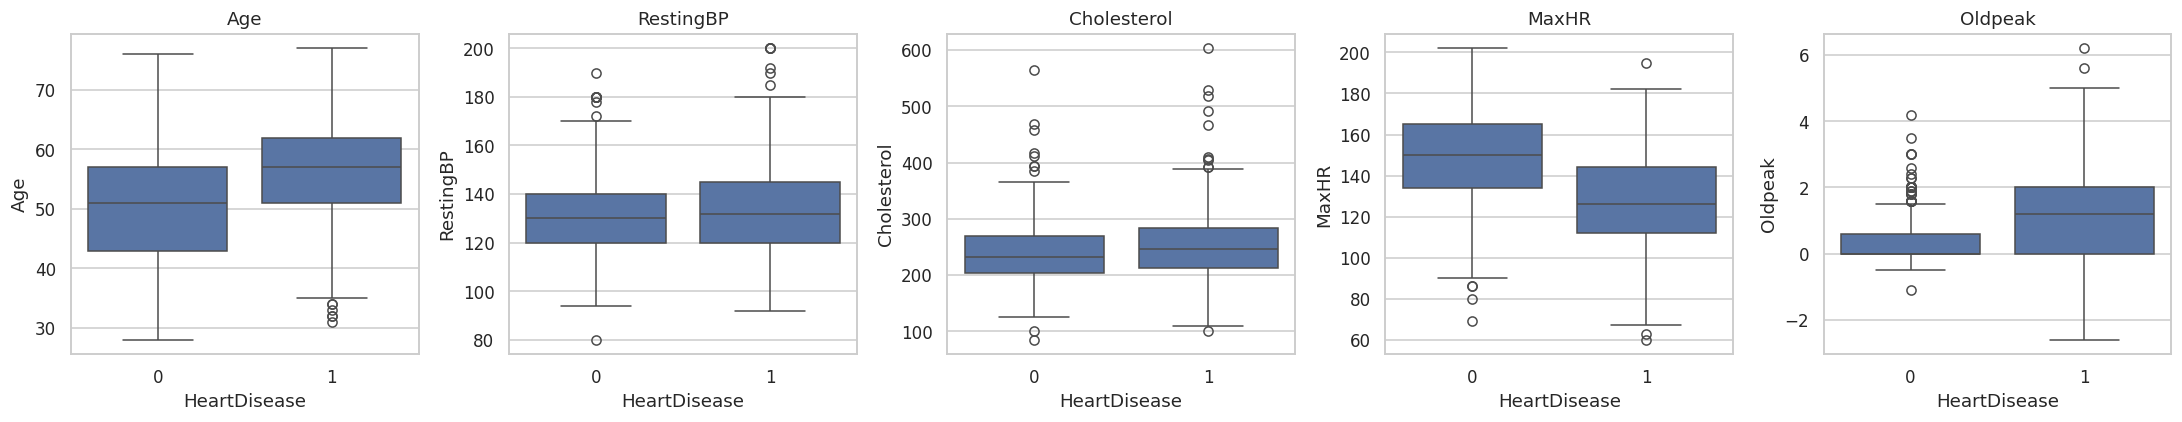

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df_clean, x='HeartDisease', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

In [11]:
# Heart-disease rate by category
for col in cat_cols:
    print(f'--- {col} ---')
    print((df_clean.groupby(col)['HeartDisease'].mean() * 100).round(1).sort_values(ascending=False).astype(str) + ' %\n')

--- Sex ---
Sex
M    63.2 %\n
F    25.9 %\n
Name: HeartDisease, dtype: object
--- ChestPainType ---
ChestPainType
ASY    79.0 %\n
TA     43.5 %\n
NAP    35.5 %\n
ATA    13.9 %\n
Name: HeartDisease, dtype: object
--- RestingECG ---
RestingECG
ST        65.7 %\n
LVH       56.4 %\n
Normal    51.6 %\n
Name: HeartDisease, dtype: object
--- ExerciseAngina ---
ExerciseAngina
Y    85.2 %\n
N    35.1 %\n
Name: HeartDisease, dtype: object
--- ST_Slope ---
ST_Slope
Flat    82.8 %\n
Down    77.8 %\n
Up      19.7 %\n
Name: HeartDisease, dtype: object


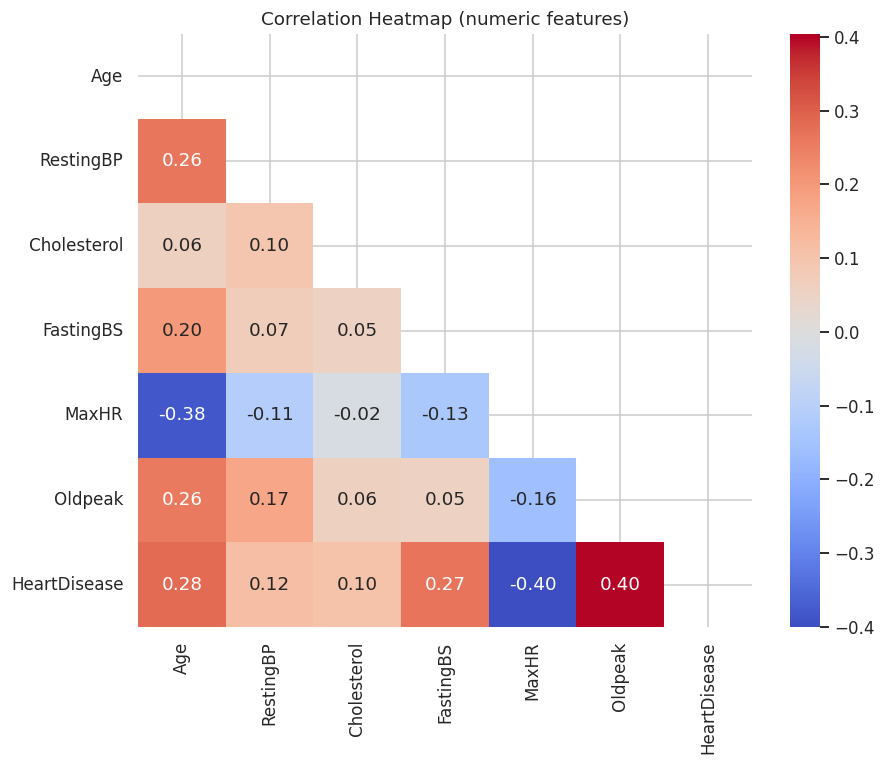

In [12]:
plt.figure(figsize=(9, 7))
corr = df_clean.select_dtypes(include='number').corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (numeric features)')
plt.show()

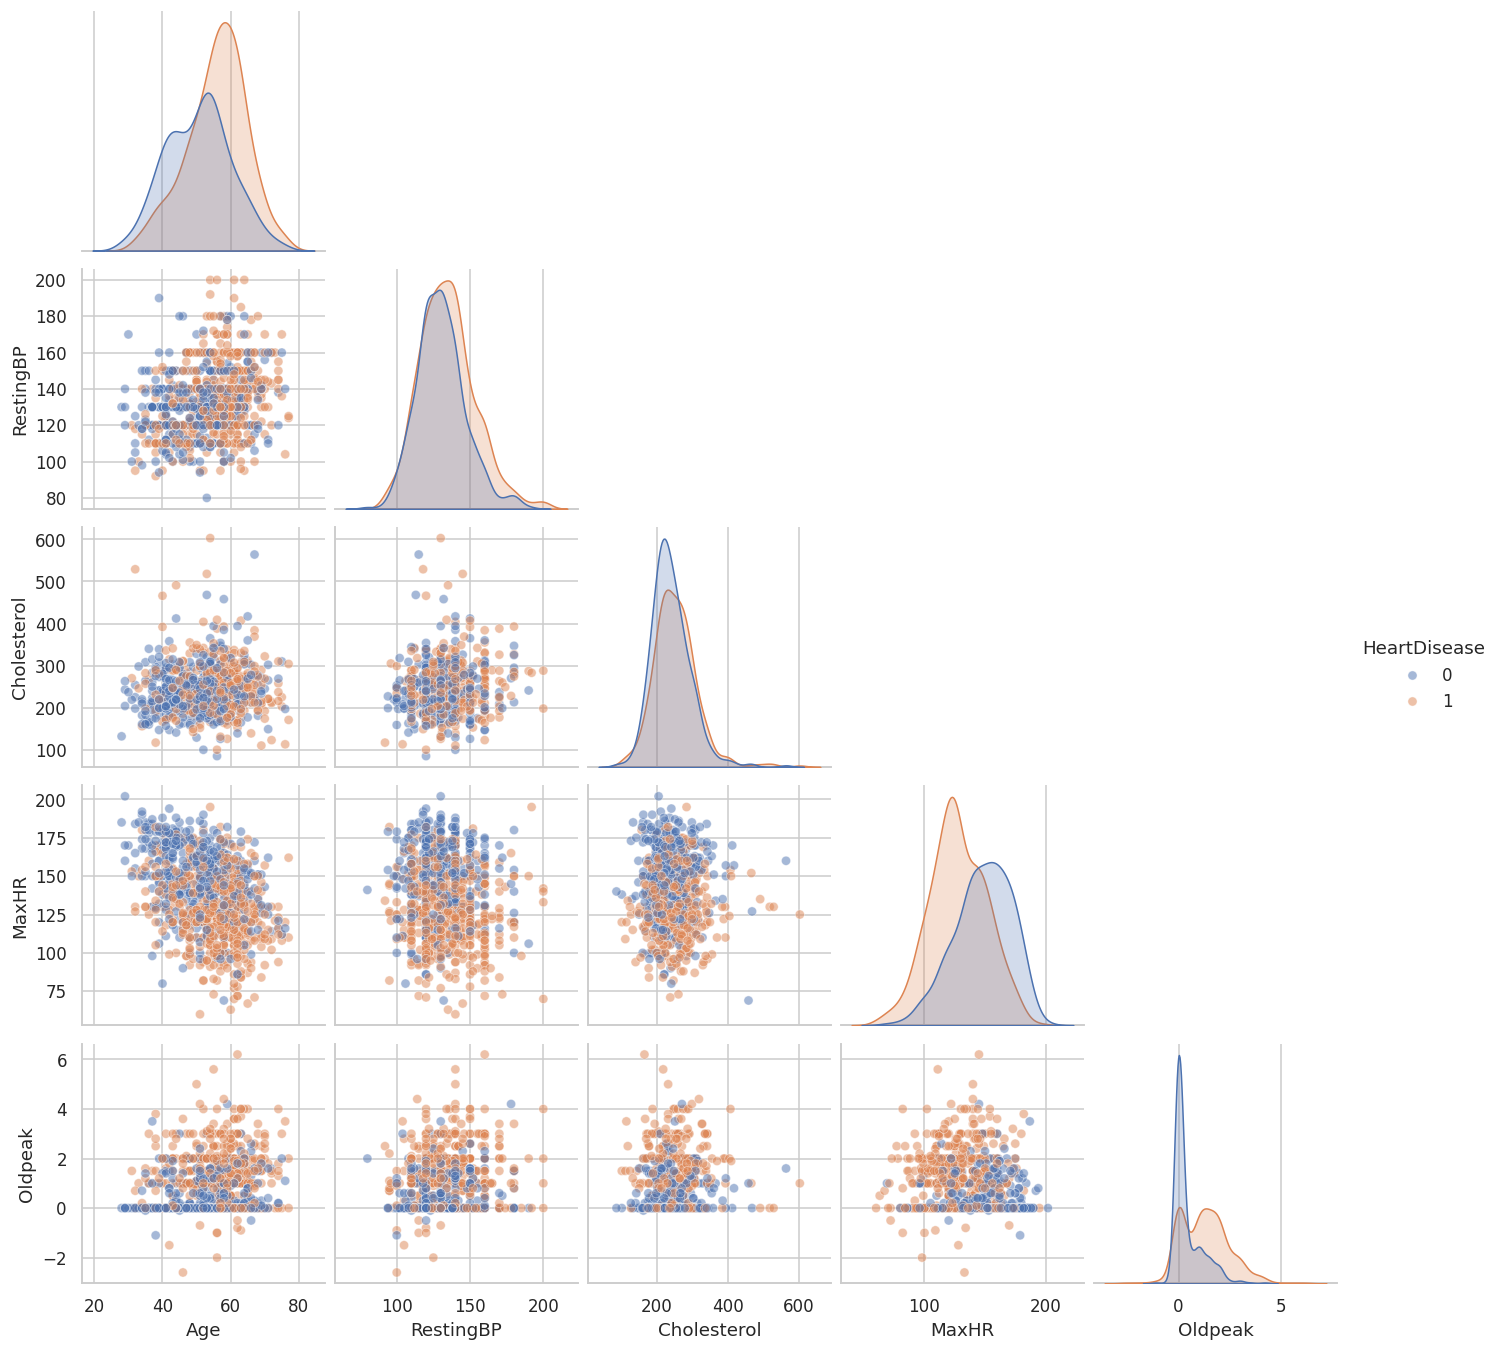

In [13]:
sns.pairplot(df_clean[num_cols + ['HeartDisease']], hue='HeartDisease', corner=True, plot_kws={'alpha': 0.5})
plt.show()

## 6. Train / Test Split & Preprocessing Pipeline

- **Stratified** 80/20 split keeps the class ratio identical in train and test.
- Numeric features → median imputation + `StandardScaler`
- Categorical features → `OneHotEncoder`
- All preprocessing lives inside a `Pipeline`, so it is fitted **only on training folds** (no data leakage) and the whole thing can be saved as one file.

In [14]:
X = df_clean.drop('HeartDisease', axis=1)
y = df_clean['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train class ratio:', y_train.mean().round(3), '| Test class ratio:', y_test.mean().round(3))

Train: (734, 11) | Test: (184, 11)
Train class ratio: 0.553 | Test class ratio: 0.554


In [15]:
binary_cols = ['FastingBS']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipe = Pipeline([
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', categorical_pipe, cat_cols),
    ('bin', 'passthrough', binary_cols)
])
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'RestingBP', 'Cholesterol', 'MaxHR',
                                  'Oldpeak']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'))]),
                                 ['Sex', 'ChestPainType', 'RestingECG',
                                  'ExerciseAngina', 'ST_Slope']),
                                ('bin', 'passthrough', ['FastingBS'])])

## 7. Define All Models

In [16]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN':                 KNeighborsClassifier(),
    'Naive Bayes':         GaussianNB(),
    'Decision Tree':       DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM (RBF)':           SVC(probability=True, random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'Extra Trees':         ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE),
    'Gradient Boosting':   GradientBoostingClassifier(random_state=RANDOM_STATE),
    'AdaBoost':            AdaBoostClassifier(random_state=RANDOM_STATE),
    'Neural Network (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=RANDOM_STATE),
}
if HAS_XGB:
    models['XGBoost'] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                      eval_metric='logloss', random_state=RANDOM_STATE)
if HAS_LGBM:
    models['LightGBM'] = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                        random_state=RANDOM_STATE, verbose=-1)

def make_pipeline(estimator):
    return Pipeline([('prep', clone(preprocessor)), ('clf', clone(estimator))])

pipelines = {name: make_pipeline(m) for name, m in models.items()}
print(f'{len(pipelines)} models ready:', list(pipelines))

12 models ready: ['Logistic Regression', 'KNN', 'Naive Bayes', 'Decision Tree', 'SVM (RBF)', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'AdaBoost', 'Neural Network (MLP)', 'XGBoost', 'LightGBM']


## 8. Cross-Validation Comparison (5-Fold Stratified)

Cross-validation is more reliable than a single train/test split — it shows both the **mean score** and the **stability** (std) of each model.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        'Model': name,
        'Accuracy':  scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall':    scores['test_recall'].mean(),
        'F1':        scores['test_f1'].mean(),
        'ROC-AUC':   scores['test_roc_auc'].mean(),
        'F1 Std':    scores['test_f1'].std(),
    })
    print(f'done: {name}')

cv_results = pd.DataFrame(cv_rows).sort_values('F1', ascending=False).reset_index(drop=True)
cv_results.round(4).style.background_gradient(cmap='Greens', subset=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'])

done: Logistic Regression
done: KNN
done: Naive Bayes
done: Decision Tree
done: SVM (RBF)
done: Random Forest
done: Extra Trees
done: Gradient Boosting
done: AdaBoost
done: Neural Network (MLP)
done: XGBoost
done: LightGBM


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,F1 Std
0,XGBoost,0.869200,0.883400,0.881800,0.882100,0.925300,0.016000
1,LightGBM,0.865100,0.871400,0.889200,0.879500,0.915800,0.015000
2,Random Forest,0.859700,0.854700,0.904100,0.877500,0.924800,0.029900
3,SVM (RBF),0.857000,0.852600,0.901600,0.875300,0.914800,0.030100
4,Gradient Boosting,0.854300,0.870300,0.869500,0.868900,0.917900,0.023200
5,Logistic Regression,0.851500,0.862500,0.874500,0.867500,0.921900,0.025000
6,Extra Trees,0.850200,0.854000,0.884300,0.867200,0.918600,0.021300
7,AdaBoost,0.850200,0.859800,0.874400,0.866400,0.917400,0.020700
8,KNN,0.842000,0.843000,0.879400,0.860500,0.885300,0.035200
9,Naive Bayes,0.839300,0.857800,0.854800,0.855200,0.915200,0.035300


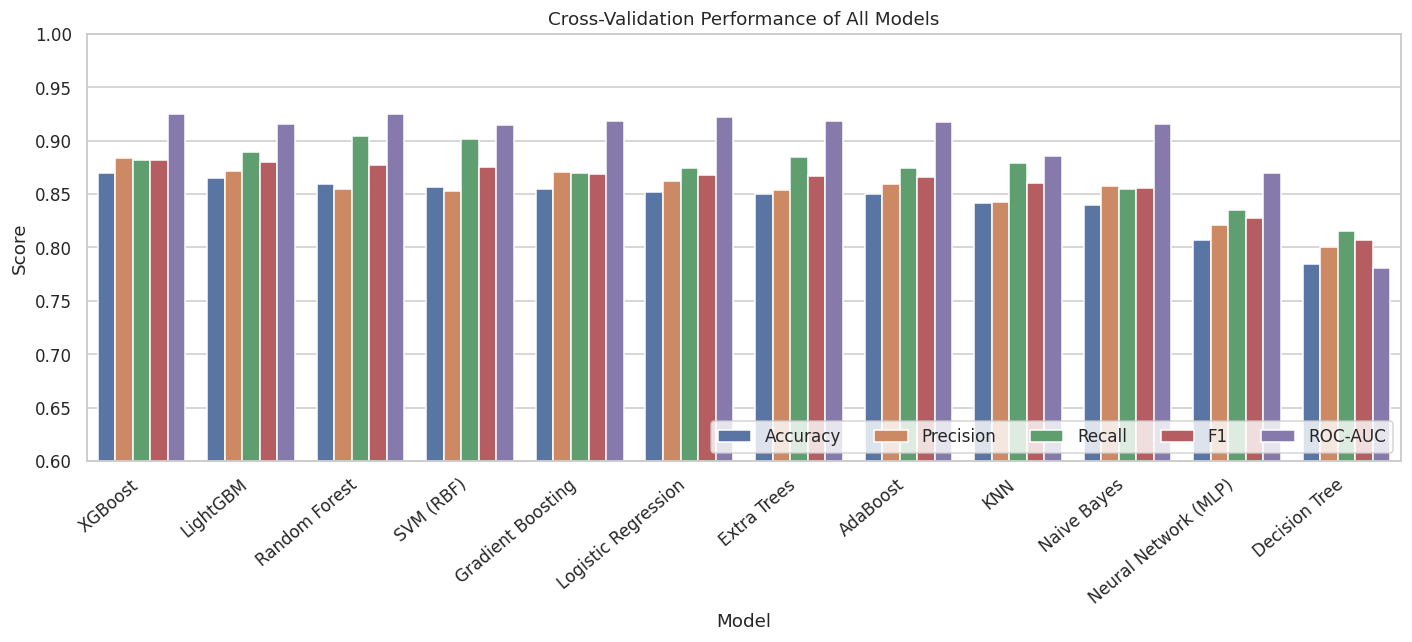

In [18]:
plot_df = cv_results.melt(id_vars='Model', value_vars=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
                          var_name='Metric', value_name='Score')
plt.figure(figsize=(13, 6))
sns.barplot(data=plot_df, x='Model', y='Score', hue='Metric')
plt.xticks(rotation=40, ha='right'); plt.ylim(0.6, 1.0)
plt.title('Cross-Validation Performance of All Models')
plt.legend(loc='lower right', ncol=5)
plt.tight_layout(); plt.show()

## 9. Hyperparameter Tuning

We tune the most promising model families with cross-validated search, optimizing **F1-score**
(a balance of precision and recall — important in medical screening).

In [19]:
param_grids = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), {
        'clf__C': [0.01, 0.1, 1, 10, 100],
        'clf__penalty': ['l2'],
        'clf__solver': ['lbfgs', 'liblinear'],
    }),
    'KNN': (KNeighborsClassifier(), {
        'clf__n_neighbors': list(range(3, 26, 2)),
        'clf__weights': ['uniform', 'distance'],
        'clf__p': [1, 2],
    }),
    'SVM (RBF)': (SVC(probability=True, random_state=RANDOM_STATE), {
        'clf__C': [0.1, 1, 10, 50],
        'clf__gamma': ['scale', 0.01, 0.05, 0.1],
        'clf__kernel': ['rbf', 'linear'],
    }),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE), {
        'clf__n_estimators': [200, 400],
        'clf__max_depth': [None, 4, 6, 8],
        'clf__min_samples_split': [2, 5, 10],
        'clf__min_samples_leaf': [1, 2, 4],
        'clf__max_features': ['sqrt', 'log2'],
    }),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE), {
        'clf__n_estimators': [100, 200, 300],
        'clf__learning_rate': [0.01, 0.05, 0.1],
        'clf__max_depth': [2, 3, 4],
        'clf__subsample': [0.7, 0.9, 1.0],
    }),
}
if HAS_XGB:
    param_grids['XGBoost'] = (XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE), {
        'clf__n_estimators': [150, 300, 500],
        'clf__learning_rate': [0.01, 0.05, 0.1],
        'clf__max_depth': [2, 3, 4, 5],
        'clf__subsample': [0.7, 0.9, 1.0],
        'clf__colsample_bytree': [0.7, 0.9, 1.0],
    })

tuned = {}        # name -> fitted search object
tuning_rows = []
for name, (est, grid) in param_grids.items():
    n_combos = int(np.prod([len(v) for v in grid.values()]))
    SearchCV = GridSearchCV if n_combos <= 40 else RandomizedSearchCV
    kwargs = {} if SearchCV is GridSearchCV else {'n_iter': 30, 'random_state': RANDOM_STATE}
    search = SearchCV(make_pipeline(est), grid, scoring='f1', cv=cv, n_jobs=-1, **kwargs)
    search.fit(X_train, y_train)
    tuned[name] = search
    tuning_rows.append({'Model': name, 'Best CV F1': search.best_score_, 'Best Params': search.best_params_})
    print(f'tuned: {name:<20} best CV F1 = {search.best_score_:.4f}')

pd.DataFrame(tuning_rows).sort_values('Best CV F1', ascending=False).reset_index(drop=True)

tuned: Logistic Regression  best CV F1 = 0.8702
tuned: KNN                  best CV F1 = 0.8798
tuned: SVM (RBF)            best CV F1 = 0.8792
tuned: Random Forest        best CV F1 = 0.8777
tuned: Gradient Boosting    best CV F1 = 0.8811
tuned: XGBoost              best CV F1 = 0.8867


,Model,Best CV F1,Best Params
0,XGBoost,0.886666,"{'clf__subsample': 0.9, 'clf__n_estimators': 1..."
1,Gradient Boosting,0.881056,"{'clf__subsample': 0.9, 'clf__n_estimators': 1..."
2,KNN,0.879756,"{'clf__weights': 'uniform', 'clf__p': 1, 'clf_..."
3,SVM (RBF),0.879238,"{'clf__C': 1, 'clf__gamma': 0.1, 'clf__kernel'..."
4,Random Forest,0.877674,"{'clf__n_estimators': 400, 'clf__min_samples_s..."
5,Logistic Regression,0.870160,"{'clf__C': 0.1, 'clf__penalty': 'l2', 'clf__so..."


## 10. Ensemble Models

Combining several strong, diverse models often beats any single one.
- **Soft Voting:** averages predicted probabilities.
- **Stacking:** a meta-learner (Logistic Regression) learns how to best combine the base models.

In [20]:
base_estimators = [(name.replace(' ', '_'), clone(s.best_estimator_.named_steps['clf']))
                   for name, s in tuned.items()]

voting = make_pipeline(VotingClassifier(estimators=base_estimators, voting='soft', n_jobs=-1))
stacking = make_pipeline(StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5, n_jobs=-1))

ensembles = {'Soft Voting Ensemble': voting, 'Stacking Ensemble': stacking}
for name, pipe in ensembles.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print(f"{name:<22} CV F1 = {scores['test_f1'].mean():.4f} | CV ROC-AUC = {scores['test_roc_auc'].mean():.4f}")

Soft Voting Ensemble   CV F1 = 0.8838 | CV ROC-AUC = 0.9279
Stacking Ensemble      CV F1 = 0.8848 | CV ROC-AUC = 0.9285


## 11. Final Evaluation on the Hold-Out Test Set

All models (baseline, tuned and ensembles) are fitted on the training set and evaluated **once** on the unseen test set.

In [21]:
final_models = {}
final_models.update({f'{n} (baseline)': p for n, p in pipelines.items()})
final_models.update({f'{n} (tuned)': s.best_estimator_ for n, s in tuned.items()})
final_models.update(ensembles)

rows = []
for name, pipe in final_models.items():
    pipe.fit(X_train, y_train)        # tuned estimators are already fitted; refit is harmless
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, proba),
    })

test_results = pd.DataFrame(rows).sort_values(['F1', 'ROC-AUC'], ascending=False).reset_index(drop=True)
test_results.round(4).style.background_gradient(cmap='Blues', subset=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'])

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,AdaBoost (baseline),0.891300,0.910000,0.892200,0.901000,0.921000
1,XGBoost (tuned),0.885900,0.885700,0.911800,0.898600,0.937500
2,Logistic Regression (baseline),0.885900,0.885700,0.911800,0.898600,0.932900
3,Extra Trees (baseline),0.880400,0.870400,0.921600,0.895200,0.934800
4,Stacking Ensemble,0.880400,0.900000,0.882400,0.891100,0.938100
5,KNN (tuned),0.880400,0.900000,0.882400,0.891100,0.934900
6,XGBoost (baseline),0.880400,0.908200,0.872500,0.890000,0.927300
7,Gradient Boosting (baseline),0.875000,0.876200,0.902000,0.888900,0.923400
8,Logistic Regression (tuned),0.875000,0.891100,0.882400,0.886700,0.930900
9,Random Forest (baseline),0.875000,0.891100,0.882400,0.886700,0.930200


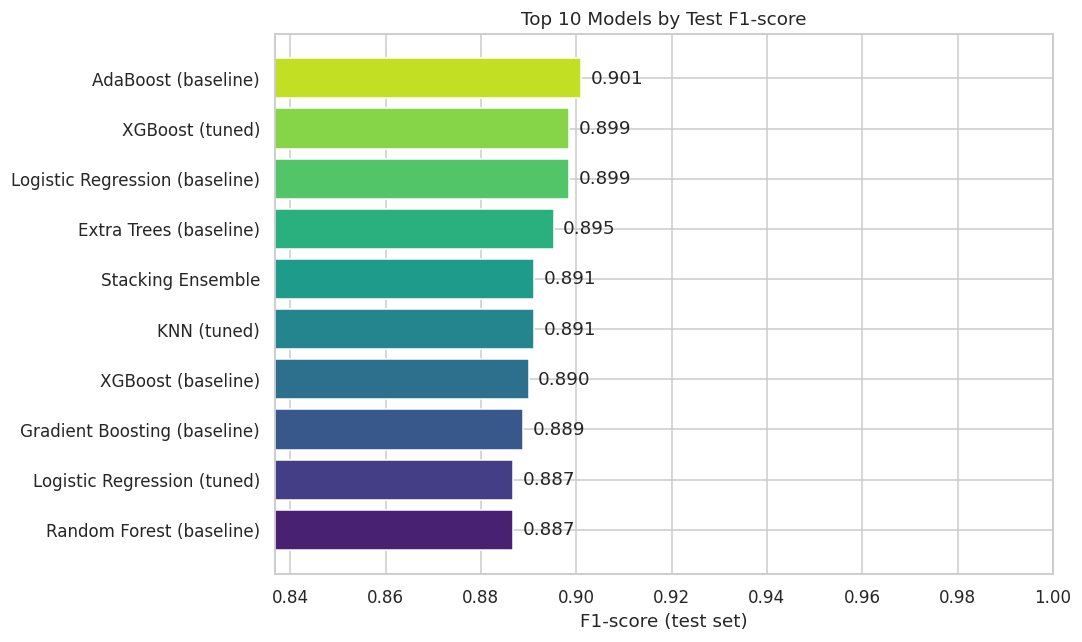

In [22]:
top = test_results.head(10).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top['Model'], top['F1'], color=sns.color_palette('viridis', len(top)))
for i, v in enumerate(top['F1']):
    plt.text(v + 0.002, i, f'{v:.3f}', va='center')
plt.xlim(top['F1'].min() - 0.05, 1.0)
plt.xlabel('F1-score (test set)'); plt.title('Top 10 Models by Test F1-score')
plt.tight_layout(); plt.show()

## 12. Best Model — Detailed Analysis

In [23]:
best_name = test_results.loc[0, 'Model']
best_model = final_models[best_name]
print('🏆 Best model:', best_name)

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print('\n' + classification_report(y_test, y_pred, target_names=['Healthy', 'Heart Disease']))

🏆 Best model: AdaBoost (baseline)

               precision    recall  f1-score   support

      Healthy       0.87      0.89      0.88        82
Heart Disease       0.91      0.89      0.90       102

     accuracy                           0.89       184
    macro avg       0.89      0.89      0.89       184
 weighted avg       0.89      0.89      0.89       184



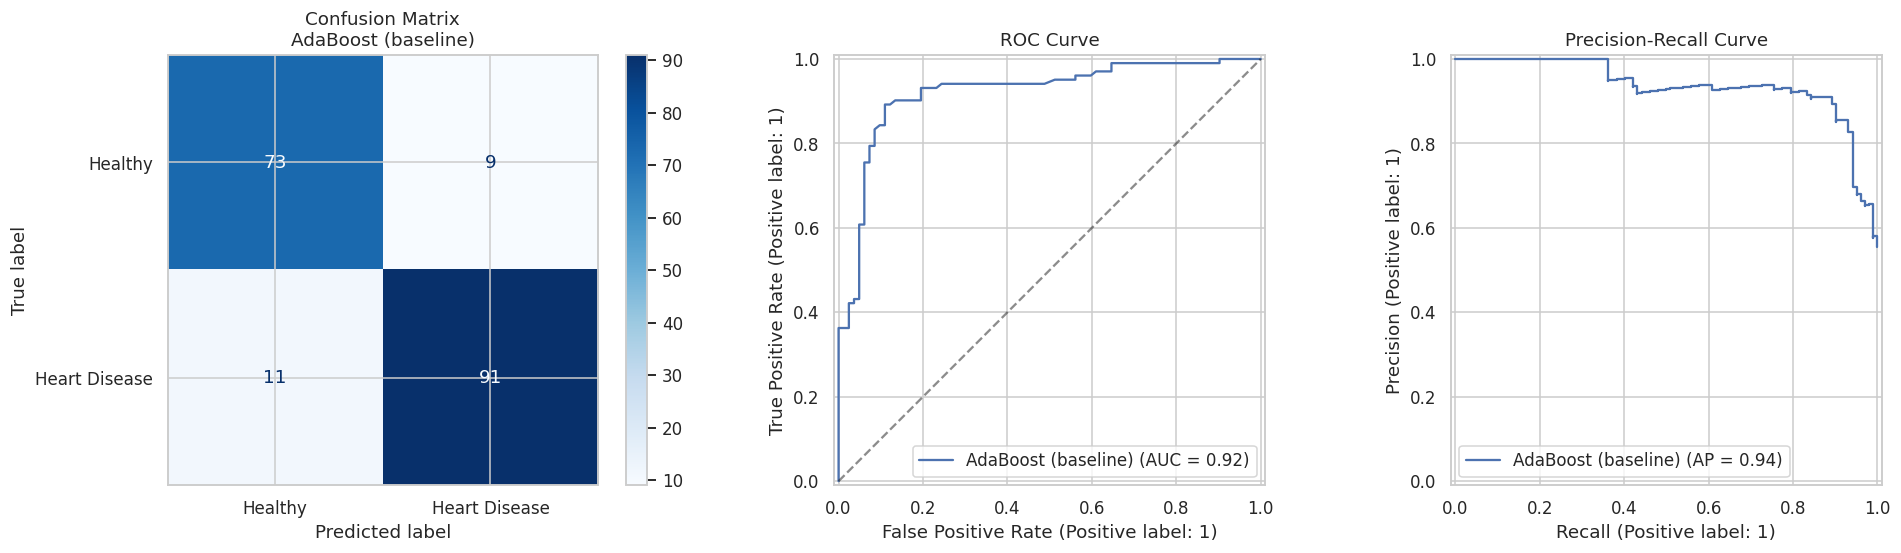

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Healthy', 'Heart Disease'],
                                        cmap='Blues', ax=axes[0])
axes[0].set_title(f'Confusion Matrix\n{best_name}')

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title('ROC Curve')

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2], name=best_name)
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout(); plt.show()

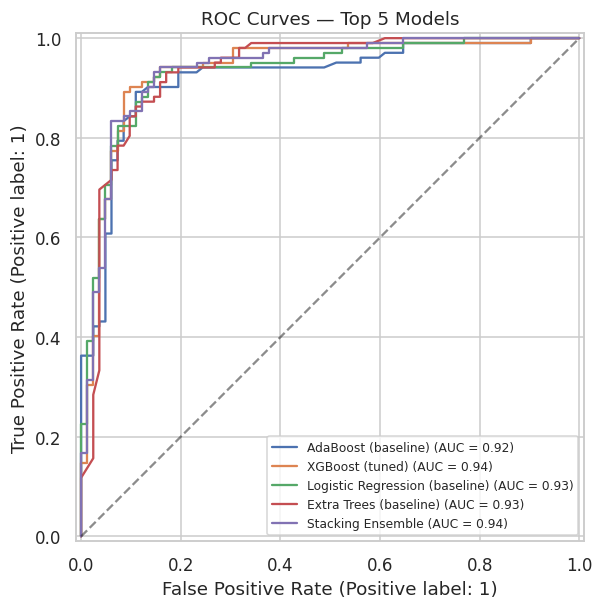

In [25]:
# ROC curves of the top 5 models together
plt.figure(figsize=(8, 6))
for name in test_results['Model'].head(5):
    RocCurveDisplay.from_estimator(final_models[name], X_test, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.title('ROC Curves — Top 5 Models'); plt.legend(loc='lower right', fontsize=8)
plt.show()

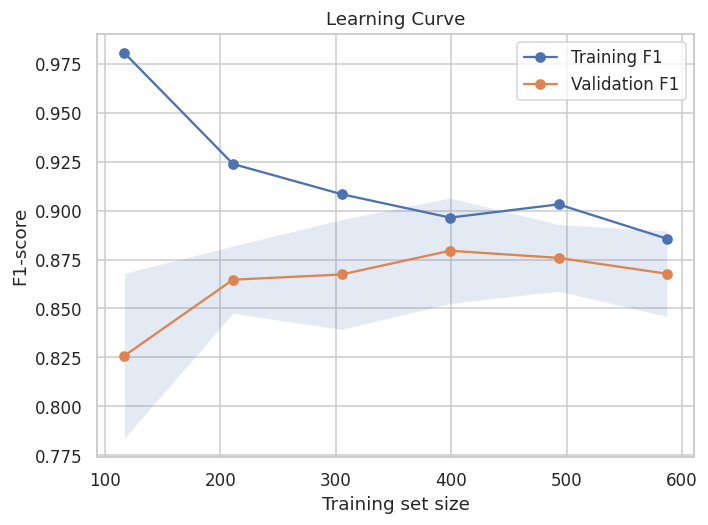

In [26]:
# Learning curve: is the model over/under-fitting?
sizes, train_sc, val_sc = learning_curve(clone(best_model), X_train, y_train, cv=cv, scoring='f1',
                                         train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1)
plt.figure(figsize=(7, 5))
plt.plot(sizes, train_sc.mean(1), 'o-', label='Training F1')
plt.plot(sizes, val_sc.mean(1), 'o-', label='Validation F1')
plt.fill_between(sizes, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.15)
plt.xlabel('Training set size'); plt.ylabel('F1-score'); plt.title('Learning Curve'); plt.legend()
plt.show()

## 13. Model Explainability — Which Features Matter?

**Permutation importance** measures how much the F1-score drops when one feature is randomly shuffled.
It works with any model and uses the original (un-encoded) feature names.

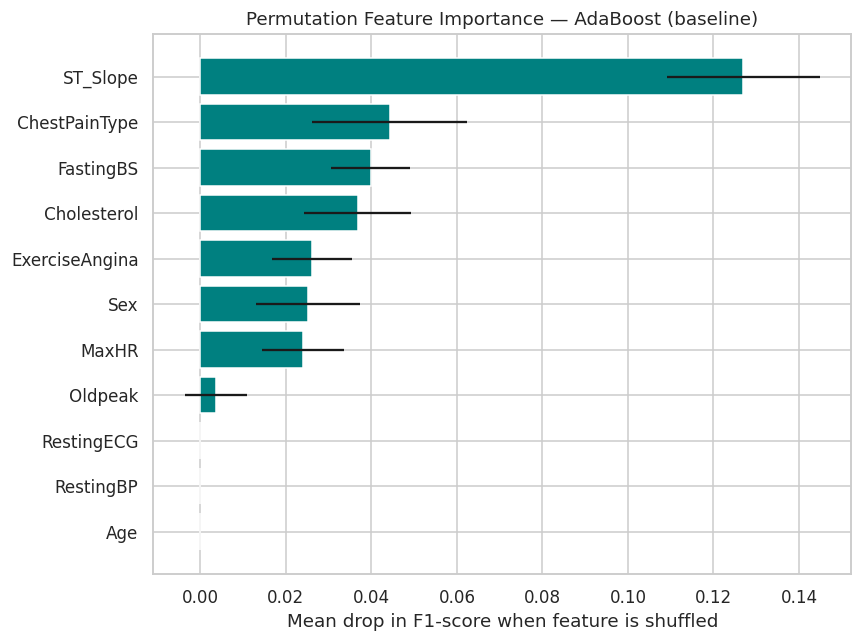

,Feature,Importance,Std
0,ST_Slope,0.126933,0.017902
1,ChestPainType,0.044308,0.018164
2,FastingBS,0.039807,0.009181
3,Cholesterol,0.036848,0.012507
4,ExerciseAngina,0.026086,0.009400
5,Sex,0.025196,0.012131
6,MaxHR,0.023971,0.009631
7,Oldpeak,0.003610,0.007228
8,RestingECG,0.000000,0.000000
9,Age,0.000000,0.000000


In [27]:
perm = permutation_importance(best_model, X_test, y_test, scoring='f1',
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({'Feature': X_test.columns, 'Importance': perm.importances_mean, 'Std': perm.importances_std})
         .sort_values('Importance', ascending=True))

plt.figure(figsize=(8, 6))
plt.barh(imp['Feature'], imp['Importance'], xerr=imp['Std'], color='teal')
plt.xlabel('Mean drop in F1-score when feature is shuffled')
plt.title(f'Permutation Feature Importance — {best_name}')
plt.tight_layout(); plt.show()
imp.sort_values('Importance', ascending=False).reset_index(drop=True)

## 14. Save the Final Model

In [28]:
# The saved object is the FULL pipeline: preprocessing + model, so no separate scaler/encoder is needed.
joblib.dump(best_model, 'heart_disease_model.pkl')
joblib.dump(list(X.columns), 'feature_columns.pkl')
test_results.to_csv('model_comparison_results.csv', index=False)
print('Saved: heart_disease_model.pkl, feature_columns.pkl, model_comparison_results.csv')

Saved: heart_disease_model.pkl, feature_columns.pkl, model_comparison_results.csv


## 15. Load the Model & Predict for a New Patient

In [29]:
loaded_model = joblib.load('heart_disease_model.pkl')

new_patient = pd.DataFrame([{
    'Age': 58, 'Sex': 'M', 'ChestPainType': 'ASY', 'RestingBP': 140, 'Cholesterol': 260,
    'FastingBS': 1, 'RestingECG': 'Normal', 'MaxHR': 115, 'ExerciseAngina': 'Y',
    'Oldpeak': 2.0, 'ST_Slope': 'Flat'
}])

pred = loaded_model.predict(new_patient)[0]
prob = loaded_model.predict_proba(new_patient)[0, 1]
print('Prediction :', '⚠️ Heart Disease' if pred == 1 else '✅ No Heart Disease')
print(f'Probability of heart disease: {prob:.1%}')

Prediction : ⚠️ Heart Disease
Probability of heart disease: 71.0%


## 16. Conclusion

- The data contained hidden missing values (`Cholesterol = 0`, `RestingBP = 0`), handled with median imputation inside the pipeline.
- **12+ models** were compared using stratified 5-fold cross-validation, then the strongest were **tuned** and combined into **Voting / Stacking ensembles**.
- The best model was chosen on an untouched test set and explained with permutation importance.
- Key predictors typically include **ST_Slope, ChestPainType, ExerciseAngina, Oldpeak and Sex** (see the importance chart above).
- The full pipeline is saved as a single `.pkl` file and can be deployed (e.g. Streamlit / Flask / FastAPI).

**Future work:** SHAP explanations, probability-threshold tuning to maximize recall for screening, a Streamlit web app, and validation on external datasets.

> ⚠️ *This project is for educational purposes and is not a substitute for professional medical diagnosis.*